<a href="https://colab.research.google.com/github/ding11m/Heart_Disease_Model/blob/main/%5BUC%5DHeart_Disease_Model_D2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/"
    "processed.cleveland.data"
)

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:

print(df.info())
print(df.describe())
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.68976

In [4]:

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert all columns to numeric values
for col in df.columns:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

# Convert target into binary categories
# 0 = No recorded heart disease
# 1 = Recorded heart disease
df["target"] = (df["target"] > 0).astype(int)

print("Missing values:")
print(df.isnull().sum())

print("Records after cleaning:", len(df))


Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Records after cleaning: 303


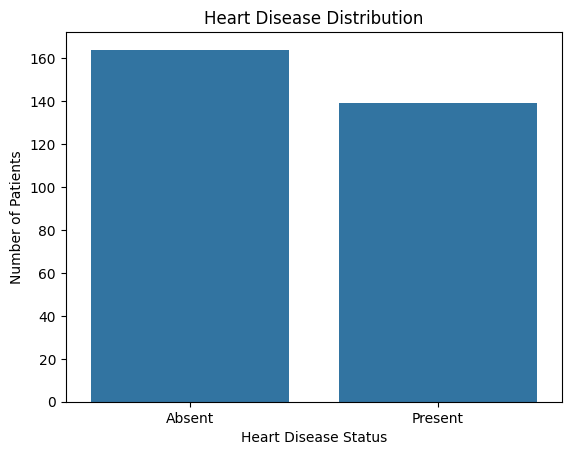

In [5]:

sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["Absent", "Present"])
plt.show()


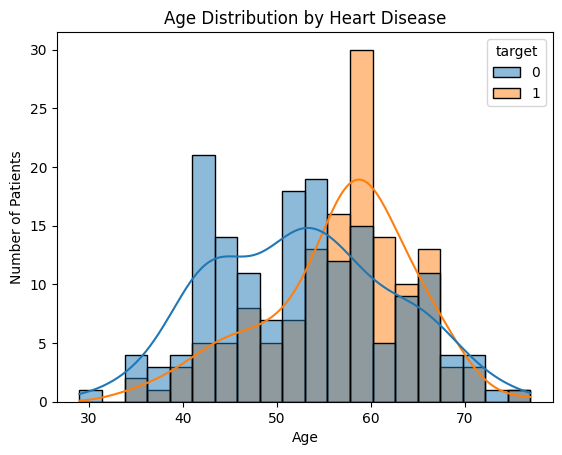

In [6]:

sns.histplot(
    data=df,
    x="age",
    hue="target",
    bins=20,
    kde=True
)

plt.title("Age Distribution by Heart Disease")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()


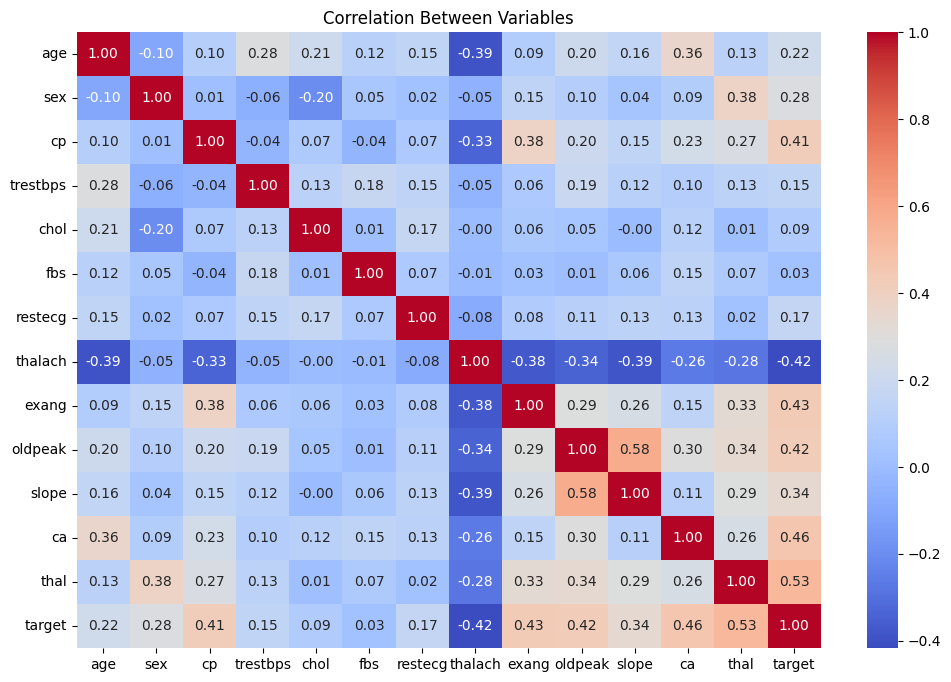

In [7]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Variables")
plt.show()


In [8]:

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 227
Testing records: 76


In [9]:

logistic_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

print(
    "Logistic Regression Accuracy:",
    accuracy_score(y_test, logistic_pred)
)

print(classification_report(
    y_test, logistic_pred,
    zero_division=0
))


Logistic Regression Accuracy: 0.868421052631579
              precision    recall  f1-score   support

           0       0.90      0.85      0.88        41
           1       0.84      0.89      0.86        35

    accuracy                           0.87        76
   macro avg       0.87      0.87      0.87        76
weighted avg       0.87      0.87      0.87        76



In [10]:

rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(
    "Random Forest Accuracy:",
    accuracy_score(y_test, rf_pred)
)

print(classification_report(
    y_test, rf_pred,
    zero_division=0
))


Random Forest Accuracy: 0.8552631578947368
              precision    recall  f1-score   support

           0       0.89      0.83      0.86        41
           1       0.82      0.89      0.85        35

    accuracy                           0.86        76
   macro avg       0.86      0.86      0.86        76
weighted avg       0.86      0.86      0.86        76



In [11]:

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

display(results)


,Model,Accuracy
0,Logistic Regression,0.868421
1,Random Forest,0.855263


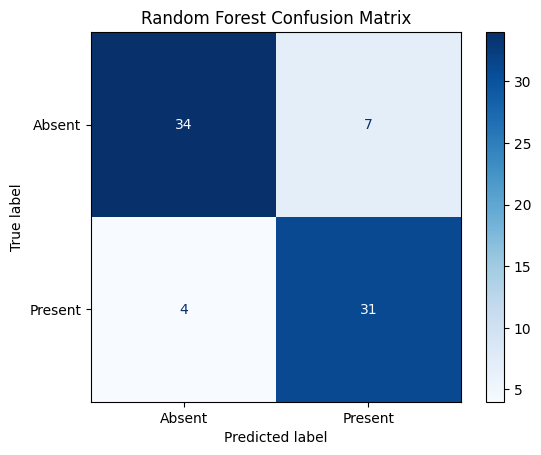

In [12]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Absent", "Present"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()


Although machine learning can help identify patterns in healthcare data, there are several ethical concerns. The dataset may not represent every population equally, which could affect the fairness of predictions. Patient privacy is also important because health information is sensitive. Our models should be considered educational tools rather than replacements for medical professionals. Before real-world use, additional testing would be needed to evaluate reliability and fairness across different patient groups.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# 1. Hyperparameter Tuning for Logistic Regression
lr_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr_param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
    "logisticregression__penalty": ["l2"],
    "logisticregression__solver": ["lbfgs", "liblinear"]
}

lr_grid = GridSearchCV(
    lr_pipe,
    lr_param_grid,
    cv=5,
    scoring="recall",  # Prioritizing recall for healthcare screening
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)

print("Best Logistic Regression Params:", lr_grid.best_params_)
print("Best CV Recall (LR):", round(lr_grid.best_score_, 4))

# 2. Hyperparameter Tuning for Random Forest
rf_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(random_state=42)
)

rf_param_grid = {
    "randomforestclassifier__n_estimators": [100, 200, 300],
    "randomforestclassifier__max_depth": [None, 5, 10, 20],
    "randomforestclassifier__min_samples_split": [2, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4]
}

rf_grid = GridSearchCV(
    rf_pipe,
    rf_param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print("Best Random Forest Params:", rf_grid.best_params_)
print("Best CV Recall (RF):", round(rf_grid.best_score_, 4))

Best Logistic Regression Params: {'logisticregression__C': 10, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'lbfgs'}
Best CV Recall (LR): 0.7786
Best Random Forest Params: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 300}
Best CV Recall (RF): 0.7595


In [14]:
# Evaluate Tuned Models on Test Set
best_lr = lr_grid.best_estimator_
best_rf = rf_grid.best_estimator_

best_lr_pred = best_lr.predict(X_test)
best_rf_pred = best_rf.predict(X_test)

best_lr_prob = best_lr.predict_proba(X_test)[:, 1]
best_rf_prob = best_rf.predict_proba(X_test)[:, 1]

print("=== Tuned Logistic Regression ===")
print("Accuracy:", round(accuracy_score(y_test, best_lr_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_lr_prob), 4))
print(classification_report(y_test, best_lr_pred, zero_division=0))

print("=== Tuned Random Forest ===")
print("Accuracy:", round(accuracy_score(y_test, best_rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_rf_prob), 4))
print(classification_report(y_test, best_rf_pred, zero_division=0))

# Side-by-Side Comparison: Baseline vs. Tuned
comparison_df = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Tuned Logistic Regression",
        "Baseline Random Forest",
        "Tuned Random Forest"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, best_lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, best_rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, best_lr_prob),
        roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, best_rf_prob)
    ]
})
display(comparison_df)

=== Tuned Logistic Regression ===
Accuracy: 0.8816
ROC-AUC: 0.9289
              precision    recall  f1-score   support

           0       0.90      0.88      0.89        41
           1       0.86      0.89      0.87        35

    accuracy                           0.88        76
   macro avg       0.88      0.88      0.88        76
weighted avg       0.88      0.88      0.88        76

=== Tuned Random Forest ===
Accuracy: 0.8553
ROC-AUC: 0.9387
              precision    recall  f1-score   support

           0       0.89      0.83      0.86        41
           1       0.82      0.89      0.85        35

    accuracy                           0.86        76
   macro avg       0.86      0.86      0.86        76
weighted avg       0.86      0.86      0.86        76



,Model,Test Accuracy,ROC-AUC
0,Baseline Logistic Regression,0.868421,0.931010
1,Tuned Logistic Regression,0.881579,0.928920
2,Baseline Random Forest,0.855263,0.942509
3,Tuned Random Forest,0.855263,0.938676


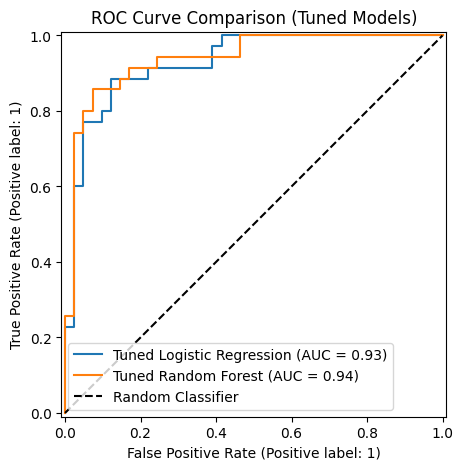

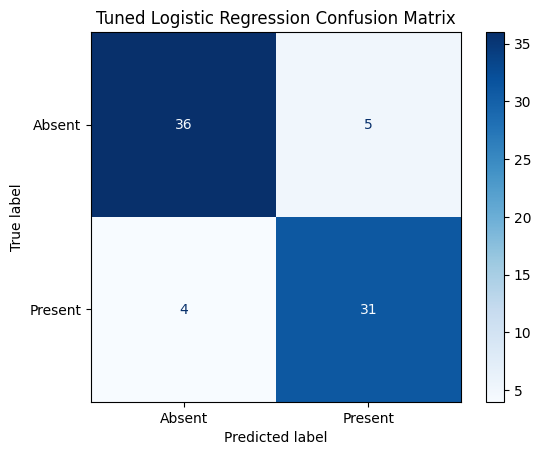

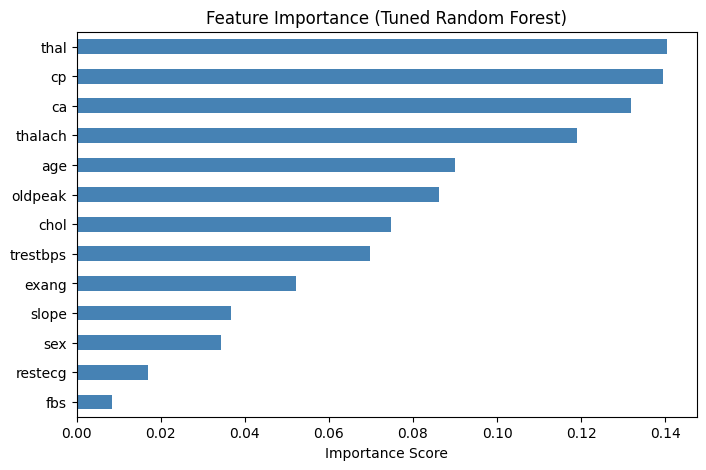

In [15]:
# 1. ROC Curve Comparison
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(best_lr, X_test, y_test, ax=ax, name="Tuned Logistic Regression")
RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=ax, name="Tuned Random Forest")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.title("ROC Curve Comparison (Tuned Models)")
plt.legend()
plt.show()

# 2. Confusion Matrix for Best Model (example: Tuned Logistic Regression)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_lr_pred,
    display_labels=["Absent", "Present"],
    cmap="Blues"
)
plt.title("Tuned Logistic Regression Confusion Matrix")
plt.show()

# 3. Feature Importance (Tuned Random Forest)
importances = best_rf.named_steps["randomforestclassifier"].feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
feat_imp.plot(kind="barh", color="steelblue")
plt.title("Feature Importance (Tuned Random Forest)")
plt.xlabel("Importance Score")
plt.show()